## Course Announcements

Due Sunday: 
- Q5
- A4
- [mid-course survey](https://forms.gle/YTy2jZRsabW6fTHUA) (for EC)
- [weekly project survey](https://forms.gle/pRqEYm8rZQH4Ezcp7) (for EC) - complete weekly

Notes:
- A1 scores released (Must click submit; fetch feedback) 

**Participation**: Doing it differently in this notebook.

1. Will need to know secret word
2. **ONLY answer the question currently being discussed**
3. CAN edit/resubmit the form multiple times - keep it open

# Inference I: Comparing Groups

Today's question: **is the difference between groups bigger than we'd expect by chance?**

- Two groups: **Student's t-test**
    - check the assumptions first (normality & equal variance)
    - when assumptions aren't met: **Welch's t-test** or **Mann-Whitney U**
    - when the data are paired: **paired t-test**
    - report an **effect size**, not just a p-value
- More than two groups: **one-way ANOVA**, then **Tukey's HSD**

(Inference II: relationships between variables, i.e. correlation & regression.)

## Contents

Lost track of where we are? Click a section to jump to it. (In JupyterLab, the table of contents sidebar, the bulleted-list icon on the left, shows the same outline and highlights the section you're in.)

- [1. Setup](#s1)
- [2. The Data](#s2)
- [3. Two Groups: The t-test](#s3) · [3a. Always Look First](#s3a) · [3b. Hypotheses](#s3b) · [3c. Check the Assumptions](#s3c) · [3d. Run the t-test](#s3d) · [3e. Effect Size](#s3e)
- [4. When Assumptions Aren't Met: Mann-Whitney U](#s4)
- [5. (If Time) Same Question, by Simulation](#s5)
- [6. Paired Data: The Paired t-test](#s6)
- [7. More Than Two Groups: ANOVA](#s7) · [7a. Run the ANOVA](#s7a) · [7b. Tukey's HSD](#s7b)
- [8. Summary: Which Test?](#s8)

## 1. Setup <a id="s1"></a>

In [1]:
import pandas as pd
import numpy as np

# Import seaborn and apply its plotting styles
import seaborn as sns
sns.set_theme(style="white",
              font_scale=2,
              rc={'axes.spines.right': False, 'axes.spines.top': False})

# import matplotlib
import matplotlib.pyplot as plt
# set plotting size parameter
plt.rcParams['figure.figsize'] = (8, 8)

# stats
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import warnings
warnings.filterwarnings('ignore')

#improve resolution
%config InlineBackend.figure_format ='retina'

## 2. The Data <a id="s2"></a>

The same data we'll use for regression on Wednesday. Each row is a US state (plus DC), at one point in time:

- `PovPct`: percent of people with incomes low enough to be classed as living in poverty
- `Brth15to17`, `Brth18to19`: birth rates for mothers ages 15-17 and 18-19
- `TeenBrth`: overall teen birth rate
- `ViolCrime`: violent crime rate

*Source: Mind On Statistics, 3rd edition, Utts and Heckard.*

In [2]:
# read in file; specify that it is tab-separated file
df = (pd.read_csv('data/teen_birth.txt', sep='\t')
      .set_index('Location'))
df.head()

,PovPct,Brth15to17,Brth18to19,ViolCrime,TeenBrth
Location,,,,,
Alabama,20.1,31.5,88.7,11.2,54.5
Alaska,7.1,18.9,73.7,9.1,39.5
Arizona,16.1,35.0,102.5,10.4,61.2
Arkansas,14.9,31.6,101.7,10.4,59.9
California,16.7,22.6,69.1,11.2,41.1


## 3. Two Groups: The t-test <a id="s3"></a>

**Question:** Do states with more violent crime have different teen birth rates than states with less?

To make two groups, we'll split states at the median violent crime rate.

(Note: this split is a *choice*. A different threshold could give a different answer, so in a real analysis you'd decide on it, and justify it, before looking at the results.)

In [3]:
# split states at the median violent crime rate
median_crime = df['ViolCrime'].median()
df['crime'] = np.where(df['ViolCrime'] > median_crime, 'high', 'low')

df['crime'].value_counts()

crime
low     26
high    25
Name: count, dtype: int64

### 3a. Always Look First <a id="s3a"></a>

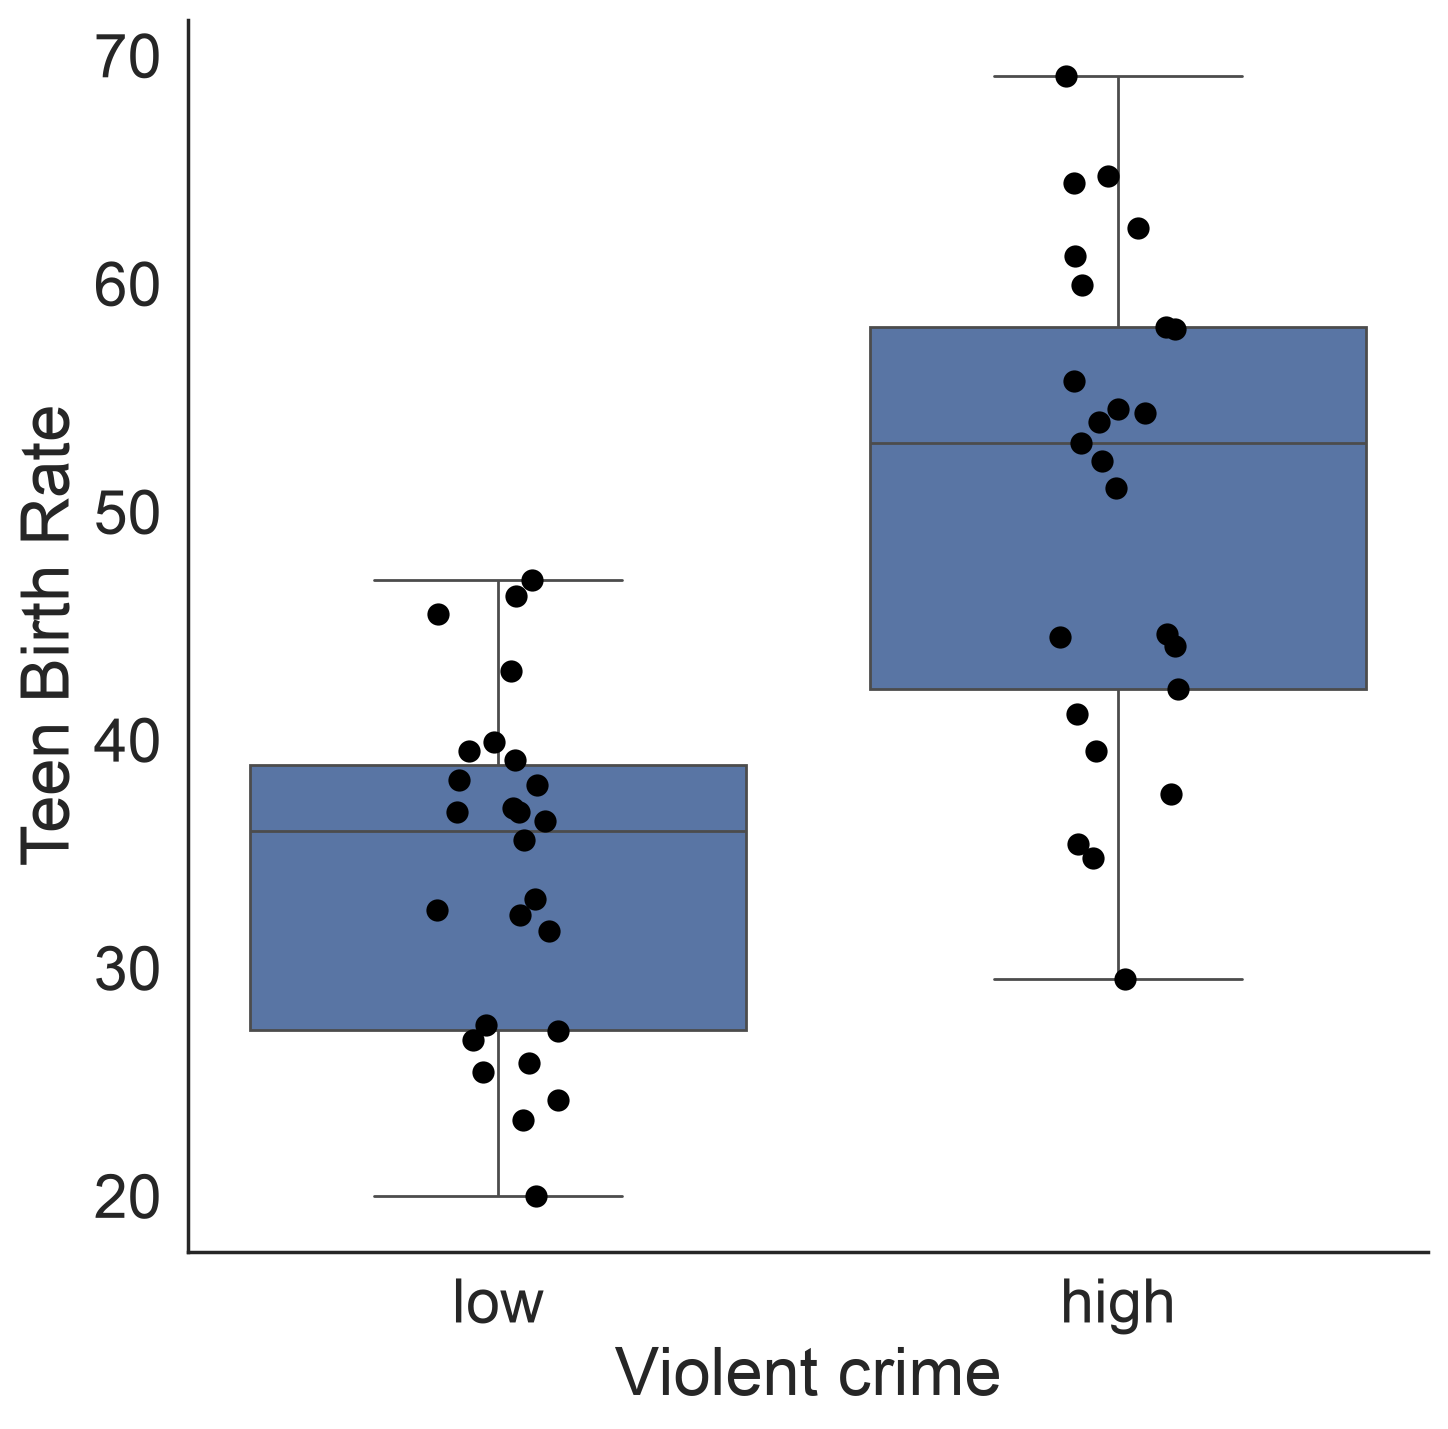

In [4]:
sns.boxplot(x='crime', y='TeenBrth', data=df, order=['low', 'high'])
sns.stripplot(x='crime', y='TeenBrth', data=df, order=['low', 'high'], color='black', size=8)
plt.xlabel('Violent crime')
plt.ylabel('Teen Birth Rate');

### 3b. Hypotheses <a id="s3b"></a>

$H_0: \mu_{high} = \mu_{low}$ (no difference in mean teen birth rate)

$H_a: \mu_{high} \ne \mu_{low}$

In [5]:
low = df.loc[df['crime'] == 'low', 'TeenBrth']
high = df.loc[df['crime'] == 'high', 'TeenBrth']

### 3c. Check the Assumptions <a id="s3c"></a>

Student's t-test assumes:

1. Data are continuous
2. Each group is (approximately) normally distributed
3. The groups have equal variance
4. Observations are independent (not paired)

#1 and #4 you know from how the data were collected. #2 and #3 you check.

#### Normality: Quantile-Quantile (QQ) Plots

A QQ plot compares the quantiles of your data to the quantiles of a normal distribution. If the data are normal, the points fall along the line.

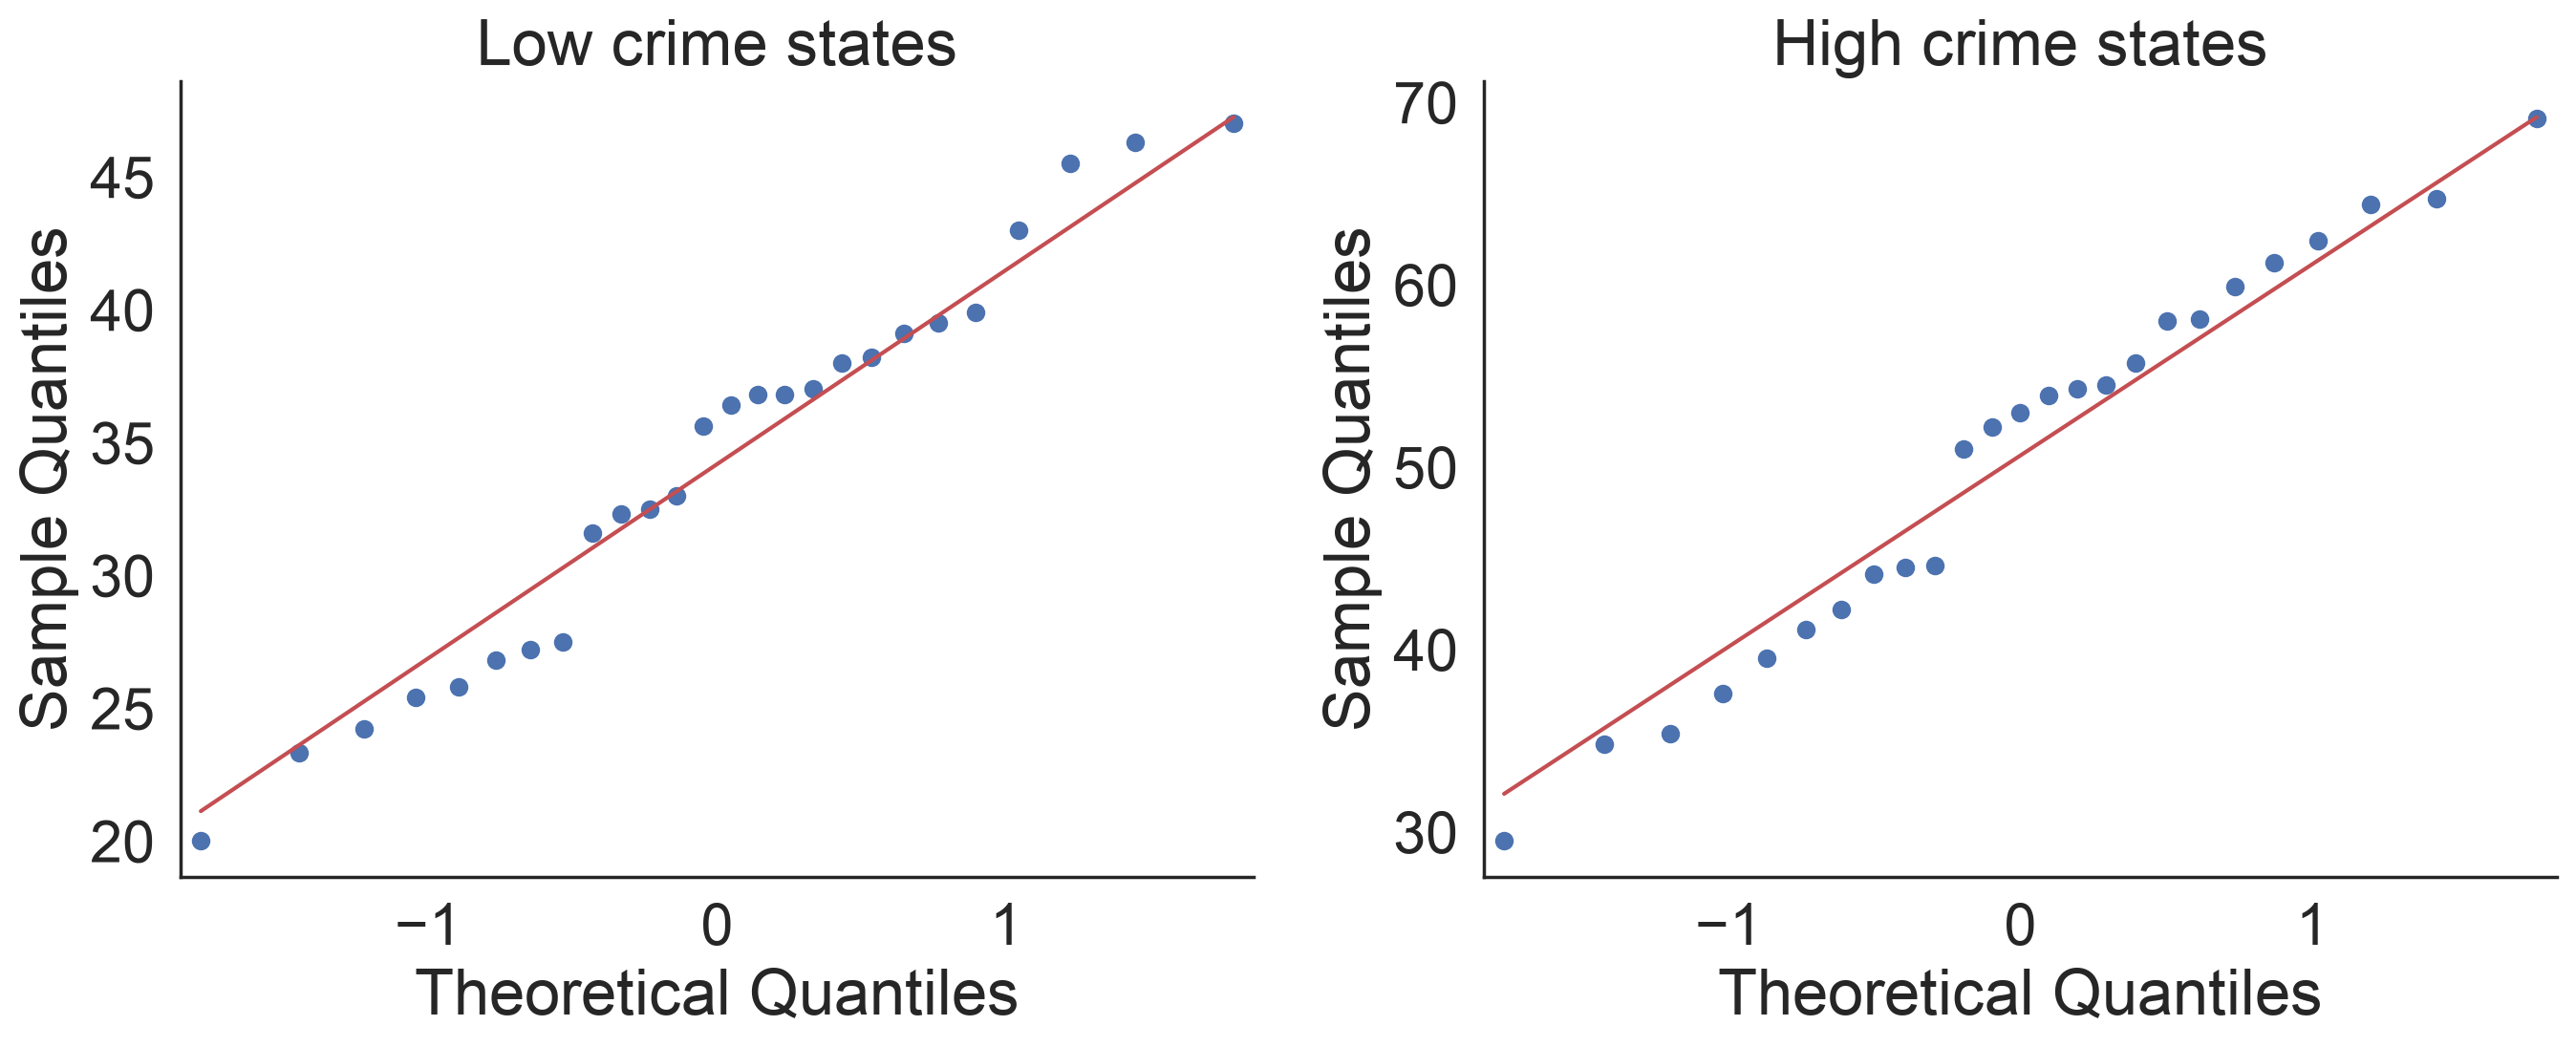

In [6]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))
sm.qqplot(low, line='s', ax=ax1)
sm.qqplot(high, line='s', ax=ax2)
ax1.set_title('Low crime states')
ax2.set_title('High crime states')
plt.tight_layout();

#### Normality: A Test

`stats.normaltest()` tests the null hypothesis that a sample comes from a normal distribution.

So here a **small** p-value is the "bad" result: it's evidence the data are *not* normal.

In [7]:
print('low: ', stats.normaltest(low))
print('high:', stats.normaltest(high))

low:  NormaltestResult(statistic=np.float64(1.2259023286236228), pvalue=np.float64(0.541749715177102))
high: NormaltestResult(statistic=np.float64(1.8373645903188378), pvalue=np.float64(0.39904451768951393))


#### Question #1 (QR Code)

What do these results tell us?

- A) Both groups are clearly not normal
- B) No evidence that either group is non-normal
- C) The low group is normal, the high group is not
- D) We can't tell anything from a normality test

https://forms.gle/72boJwHJScQ1kUWS9

![](QRCodes/09_notebook.png)

#### Equal Variance

In [8]:
df.groupby('crime')['TeenBrth'].agg(['mean', 'var', 'std', 'count'])

,mean,var,std,count
crime,,,,
high,50.628000,114.551267,10.702863,25
low,34.180769,55.614415,7.457507,26


In [9]:
# Levene's test: null hypothesis is that the groups have equal variances
stats.levene(low, high)

LeveneResult(statistic=np.float64(3.09227056300479), pvalue=np.float64(0.08490929031965543))

The variance in the high-crime group is about twice that of the low-crime group, and Levene's test is borderline.

When in doubt, use **Welch's t-test**, which doesn't assume equal variances. You lose very little when the variances *are* equal, and you're protected when they aren't.

### 3d. Run the t-test <a id="s3d"></a>

In [10]:
# Student's t-test (assumes equal variance)
stats.ttest_ind(high, low)

TtestResult(statistic=np.float64(6.388276578985204), pvalue=np.float64(5.882220867305726e-08), df=np.float64(49.0))

In [11]:
# Welch's t-test (does not assume equal variance)
stats.ttest_ind(high, low, equal_var=False)

TtestResult(statistic=np.float64(6.344153540130821), pvalue=np.float64(1.1867849494710665e-07), df=np.float64(42.70381220694482))

#### Question #2

What is our conclusion? (Question: Do states with more violent crime have different teen birth rates?)

- A) Reject the null; there is no difference in teen birth rate
- B) Reject the null; there is a difference in teen birth rate
- C) Fail to reject the null; there is no difference in teen birth rate
- D) Fail to reject the null; there is a difference in teen birth rate

### 3e. How Big Is the Difference? Effect Size <a id="s3e"></a>

A p-value tells you whether a difference is likely due to chance. It doesn't tell you whether the difference is *big*. With enough data, almost any difference is "significant."

So always report the size of the effect, too:

- the **difference in means** (with a confidence interval), in the original units
- **Cohen's d**: the difference in means divided by the pooled standard deviation (~0.2 small, ~0.5 medium, ~0.8+ large)

In [12]:
# difference in means, with a 95% confidence interval
result = stats.ttest_ind(high, low, equal_var=False)
print('difference in means:', round(high.mean() - low.mean(), 2))
print('95% CI:', result.confidence_interval())

difference in means: 16.45
95% CI: ConfidenceInterval(low=np.float64(11.217903324169473), high=np.float64(21.676558214292054))


In [13]:
def cohens_d(a, b):
    """difference in means divided by the pooled standard deviation"""
    n_a, n_b = len(a), len(b)
    pooled_sd = np.sqrt(((n_a - 1) * a.var() + (n_b - 1) * b.var()) / (n_a + n_b - 2))
    return (a.mean() - b.mean()) / pooled_sd

cohens_d(high, low)

np.float64(1.7894193128284153)

**Putting it together:** High-crime states had a teen birth rate about 16 births per 1,000 higher than low-crime states (95% CI: 11 to 22; Welch's t-test, p < 0.001; Cohen's d = 1.8).

...but remember that this is an association. It doesn't tell us that violent crime *causes* teen births. (More on confounding on in Inference-II notes.)

## 4. When Assumptions Aren't Met: Mann-Whitney U <a id="s4"></a>

If the data are clearly not normal (heavily skewed, ordinal, small samples with outliers), use a **nonparametric** test. These tests rank the data and compare the ranks, so they don't assume a distribution.

- two independent groups: **Mann-Whitney U** (aka Wilcoxon rank-sum)
- the cost: less statistical power than a t-test when the t-test's assumptions *are* met
- another option: transform the data (e.g., log) so they're closer to normal (Wednesday!)

In [ ]:
stats.mannwhitneyu(high, low)

## 5. (If Time) Same Question, by Simulation <a id="s5"></a>

Remember the coin flips? We can build a null distribution for *this* question the same way.

If crime level had nothing to do with teen birth rate, the "high"/"low" labels would be arbitrary. So: shuffle the labels many times, compute the difference in means each time, and see how often chance alone gives a difference as big as the one we observed. (This is called a **permutation test**.)

In [ ]:
rng = np.random.default_rng(108)

observed = high.mean() - low.mean()
values = df['TeenBrth'].values
is_high = (df['crime'] == 'high').values

null_diffs = []
for _ in range(10_000):
    shuffled = rng.permutation(is_high)
    null_diffs.append(values[shuffled].mean() - values[~shuffled].mean())
null_diffs = np.array(null_diffs)

sns.histplot(null_diffs)
plt.axvline(observed, color='red', linewidth=4)
plt.xlabel('Difference in means (shuffled labels)');

print('p-value:', np.mean(np.abs(null_diffs) >= abs(observed)))

None of the 10,000 shuffles produced a difference as large as the real one, so p < 1/10,000. That's the same conclusion as the t-test, without assuming normality.

## 6. Paired Data: The Paired t-test <a id="s6"></a>

The t-test above assumes the two groups are *independent*: different states in each group.

What if we compare **birth rates for 15-17 year olds vs. 18-19 year olds**? Every state has both measurements, so the measurements come in pairs. A state with high rates in one age band probably has high rates in the other.

Paired data → **paired t-test**, which tests whether the mean *within-state difference* is zero.

In [ ]:
df[['Brth15to17', 'Brth18to19']].head()

### Question #3

Which test should we use to compare `Brth15to17` and `Brth18to19`?

- A) Student's t-test
- B) Welch's t-test
- C) Paired t-test
- D) ANOVA
  
https://forms.gle/72boJwHJScQ1kUWS9

![](QRCodes/09_notebook.png)

In [ ]:
stats.ttest_rel(df['Brth18to19'], df['Brth15to17'])

## 7. More Than Two Groups: ANOVA <a id="s7"></a>

What if our categorical variable has more than two levels, like the four US Census regions?

We *could* run a t-test for every pair of regions (4 regions → 6 t-tests). But every test carries its own chance of a false positive, so the more tests we run, the more likely at least one is "significant" by chance alone (remember the jelly beans: https://xkcd.com/882/).

**One-way ANOVA** (analysis of variance) asks one question across all groups at once:

$H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4$

$H_a:$ at least one group mean is different

Same assumptions as the t-test: normality within groups, equal variances, independence.

In [ ]:
# add Census region to each state
regions = pd.read_csv('data/census_regions.csv')
regions['Location'] = regions['State'].str.replace(' ', '_')
df = df.join(regions.set_index('Location')['Region'])

df['Region'].value_counts()

In [ ]:
order = ['Northeast', 'Midwest', 'West', 'South']
sns.boxplot(x='Region', y='TeenBrth', data=df, order=order)
sns.stripplot(x='Region', y='TeenBrth', data=df, order=order, color='black', size=8)
plt.xticks(rotation=20)
plt.ylabel('Teen Birth Rate');

In [ ]:
df.groupby('Region')['TeenBrth'].agg(['mean', 'var', 'count'])

### 7a. Run the ANOVA <a id="s7a"></a>

`sm.stats.anova_oneway()` takes the values and the group labels.

Note: its default (`use_var='unequal'`) is **Welch's ANOVA**, which, like Welch's t-test, doesn't assume equal variances. The variances here differ by about 4x between regions, so the default is a good choice. Use `use_var='equal'` for the classic ANOVA.

In [ ]:
anova_result = sm.stats.anova_oneway(df['TeenBrth'], groups=df['Region'])
print('F =', round(anova_result.statistic, 2), '  p =', anova_result.pvalue)

#### Question #4

What does this ANOVA tell us?

- A) All four regions have different mean teen birth rates
- B) At least one region's mean teen birth rate differs from the others
- C) The South has the highest teen birth rate
- D) There are no differences between regions

### 7b. Which Groups Differ? Tukey's HSD <a id="s7b"></a>

ANOVA tells you *that* something differs, not *what*. To find out, follow up with a **post-hoc test**.

**Tukey's HSD** (honestly significant difference) compares every pair of groups and adjusts the p-values for the number of comparisons, so the overall false-positive rate stays at 5%.

In [ ]:
tukey_result = pairwise_tukeyhsd(df['TeenBrth'], groups=df['Region'])
print(tukey_result.summary())

How to read this table: each row is one pair of groups.

- `meandiff`: mean of `group2` minus mean of `group1`
- `p-adj`: p-value, adjusted for the number of comparisons
- `lower`, `upper`: 95% confidence interval for the difference in means
- `reject`: `True` if p-adj < 0.05 (we reject the null that these two means are equal)

#### Question #5

Which pair of regions does **not** have a significant difference in mean teen birth rate?

- A) Midwest & Northeast
- B) Midwest & West
- C) South & West
- D) Northeast & South

## 8. Summary: Which Test? <a id="s8"></a>

| Comparing... | Assumptions met | Assumptions not met |
|---|---|---|
| 2 independent groups | Student's t-test (`ttest_ind`); Welch's if variances differ (`equal_var=False`) | Mann-Whitney U (`mannwhitneyu`) |
| 2 paired measurements | paired t-test (`ttest_rel`) | Wilcoxon signed-rank (`wilcoxon`) |
| 3+ groups | one-way ANOVA (`anova_oneway`), then Tukey's HSD (`pairwise_tukeyhsd`) | Kruskal-Wallis (`kruskal`) |

And whichever test you use: **look at your data first, check assumptions, and report an effect size along with the p-value.**